# NB2 — SegFormer-B0 Semantic Segmentation

**Model:** SegFormer-B0 (`SegformerForSemanticSegmentation`, HuggingFace `transformers`)
**Shared split source:** NB0 (`438-assignment-a`) → `split.json`

This notebook loads the identical leakage-safe split produced in NB0, fine-tunes a
pretrained SegFormer-B0 encoder/decoder for binary plaque segmentation, and enforces
a minimum-50-epoch training floor with automatic continuation while validation mIoU
is still improving.

## 1. Setup & Imports (with version pins)

In [1]:
# If transformers/albumentations are missing on this Kaggle image, uncomment:
# !pip install -q transformers==4.44.2 albumentations==1.4.15

import os, json, time, random, math
from pathlib import Path

import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

import albumentations as A
from transformers import SegformerForSemanticSegmentation
import transformers

print("torch          :", torch.__version__)
print("transformers   :", transformers.__version__)
print("albumentations :", A.__version__)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device         :", DEVICE)
if DEVICE.type == "cuda":
    print("GPU            :", torch.cuda.get_device_name(0))


torch          : 2.10.0+cu128
transformers   : 5.0.0
albumentations : 2.0.8
Device         : cuda
GPU            : Tesla T4


## 2. Load the Shared Data Split from NB0

Two Kaggle data sources must be attached to this notebook:
1. `ar-plaqsegm1-ultrasound-segmentation` (original dataset — images/masks)
2. `438-assignment-a` (NB0's notebook output — `split.json`)


In [2]:
SPLIT_PATH = "/kaggle/input/notebooks/yeamins/438-assignment-a/split.json"

with open(SPLIT_PATH) as f:
    split_artifact = json.load(f)

SEED           = split_artifact["seed"]
MASK_THRESHOLD = split_artifact["mask_threshold"]

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

print(f"Loaded split -> Train: {len(split_artifact['train'])} | "
      f"Val: {len(split_artifact['val'])} | Test: {len(split_artifact['test'])}")
print(f"Seed: {SEED} | Mask threshold: {MASK_THRESHOLD}")
print(f"Removed train-side duplicates from NB0: {split_artifact['removed_train_side_duplicates']}")


Loaded split -> Train: 416 | Val: 73 | Test: 48
Seed: 42 | Mask threshold: 127
Removed train-side duplicates from NB0: ['335', '345', '346', '347']


In [3]:
# Re-point img_path / mask_path to this notebook's dataset mount
# (paths stored in split.json were written from inside NB0's environment)

NEW_DATA_ROOT = ("/kaggle/input/datasets/yeamins/ar-plaqsegm1-ultrasound-segmentation/"
                  "Ar-PlaqSegm1 First Argentine database of B-mode ul")

def fix_paths(records, new_root):
    fixed = []
    for rec in records:
        r = rec.copy()
        for key in ["img_path", "mask_path"]:
            parts = r[key].replace("\\", "/").split("/")
            filename = os.path.join(parts[-2], parts[-1])   # e.g. train/12.png
            r[key] = os.path.join(new_root, filename)
        fixed.append(r)
    return fixed

train_records = fix_paths(split_artifact["train"], NEW_DATA_ROOT)
val_records   = fix_paths(split_artifact["val"],   NEW_DATA_ROOT)
test_records  = fix_paths(split_artifact["test"],  NEW_DATA_ROOT)

test_img = cv2.imread(train_records[0]["img_path"], cv2.IMREAD_GRAYSCALE)
assert test_img is not None, "Path fix failed — check NEW_DATA_ROOT against the attached dataset mount."
print(f"Paths verified -> sample image shape: {test_img.shape}")


Paths verified -> sample image shape: (800, 800)


# Task E — Model Training (minimum 50 epochs each)

## 3. Training Configuration

Every hyperparameter used anywhere in this notebook is declared **once**, here.
Nothing below this cell hardcodes a competing value.

In [4]:
CONFIG = {
    # --- Task / data ---
    "num_classes":      2,                       # background, plaque
    "class_names":      ["background", "plaque"],
    "img_size":         512,                      # matches NB0/NB1 for a fair 3-model comparison
    "mask_threshold":   MASK_THRESHOLD,            # 127, inherited from NB0
    "seed":             SEED,                      # 42, inherited from NB0

    # --- Model / transfer learning ---
    "checkpoint":       "nvidia/segformer-b0-finetuned-ade-512-512",
    "checkpoint_domain": "ADE20K (150-class, mixed general scenes) -- chosen as the general-purpose "
                          "default per the catalogue, since ultrasound plaque frames are not an "
                          "urban-driving domain like Cityscapes.",

    # --- Optimization ---
    "optimizer":        "AdamW",
    "learning_rate":     6e-5,
    "weight_decay":       1e-4,
    "lr_schedule":       "Cosine annealing with linear warmup (first 5% of total steps)",
    "batch_size":         8,

    # --- Loss ---
    "loss_function":     "0.5 * Weighted CrossEntropy + 0.5 * Dice loss "
                          "(weighted CE combats the ~79:1 background:plaque pixel imbalance found "
                          "in NB0 Task A; Dice directly rewards mask overlap for the thin/small "
                          "plaque regions).",
    "class_weights_source": "Computed from TRAIN split pixel counts only (see Section 5 below), "
                             "not from the full-dataset EDA numbers, to avoid val/test leakage into "
                             "the weighting decision.",

    # --- Epoch policy ---
    "min_epochs":         50,     # hard floor required by the assignment
    "max_epochs":          80,     # ceiling if validation mIoU keeps improving
    "improve_patience":     8,     # stop if val mIoU hasn't improved in this many epochs (after min_epochs)
    "improve_min_delta":  1e-4,

    # --- Misc ---
    "mixed_precision":    True,
    "device":             str(DEVICE),
}

print("=== CONFIG ===")
for k, v in CONFIG.items():
    print(f"{k:22s}: {v}")


=== CONFIG ===
num_classes           : 2
class_names           : ['background', 'plaque']
img_size              : 512
mask_threshold        : 127
seed                  : 42
checkpoint            : nvidia/segformer-b0-finetuned-ade-512-512
checkpoint_domain     : ADE20K (150-class, mixed general scenes) -- chosen as the general-purpose default per the catalogue, since ultrasound plaque frames are not an urban-driving domain like Cityscapes.
optimizer             : AdamW
learning_rate         : 6e-05
weight_decay          : 0.0001
lr_schedule           : Cosine annealing with linear warmup (first 5% of total steps)
batch_size            : 8
loss_function         : 0.5 * Weighted CrossEntropy + 0.5 * Dice loss (weighted CE combats the ~79:1 background:plaque pixel imbalance found in NB0 Task A; Dice directly rewards mask overlap for the thin/small plaque regions).
class_weights_source  : Computed from TRAIN split pixel counts only (see Section 5 below), not from the full-dataset EDA numbe

## 4. Augmentation Pipeline (train-only, synchronized image+mask)

Same Albumentations pipeline established and sanity-checked in the shared
augmentation notebook — reused here unchanged for consistency across the
three model notebooks.

In [5]:
IMG_SIZE = CONFIG["img_size"]

train_transform = A.Compose([
    A.HorizontalFlip(p=0.5),
    A.Rotate(limit=15, border_mode=cv2.BORDER_CONSTANT, p=0.3),
    A.RandomBrightnessContrast(brightness_limit=0.15, contrast_limit=0.15, p=0.4),
    A.GaussNoise(var_limit=(5.0, 20.0), p=0.3),
    A.ElasticTransform(alpha=20, sigma=5, alpha_affine=5,
                        border_mode=cv2.BORDER_CONSTANT, p=0.2),
    A.Resize(IMG_SIZE, IMG_SIZE),
])

val_test_transform = A.Compose([
    A.Resize(IMG_SIZE, IMG_SIZE),
])

print("Augmentation pipeline ready (train-only; val/test get resize only).")


Augmentation pipeline ready (train-only; val/test get resize only).


/tmp/ipykernel_23/2632670665.py:7: UserWarning: Argument(s) 'var_limit' are not valid for transform GaussNoise
  A.GaussNoise(var_limit=(5.0, 20.0), p=0.3),
/tmp/ipykernel_23/2632670665.py:8: UserWarning: Argument(s) 'alpha_affine' are not valid for transform ElasticTransform
  A.ElasticTransform(alpha=20, sigma=5, alpha_affine=5,


## 5. Dataset Class for SegFormer

SegFormer-B0 was pretrained on 3-channel ImageNet-style inputs. The ultrasound
frames are single-channel, so each grayscale image is replicated to 3 channels
and normalized with ImageNet mean/std (matching what the pretrained encoder
expects) instead of the `[0,1]` single-channel scaling used for the CNN
notebooks.


In [6]:
IMAGENET_MEAN = np.array([0.485, 0.456, 0.406], dtype="float32")
IMAGENET_STD  = np.array([0.229, 0.224, 0.225], dtype="float32")

class PlaqueSegFormerDataset(Dataset):
    def __init__(self, records, transform=None, mask_threshold=MASK_THRESHOLD):
        self.records = records
        self.transform = transform
        self.mask_threshold = mask_threshold

    def __len__(self):
        return len(self.records)

    def __getitem__(self, i):
        rec = self.records[i]
        img = cv2.imread(rec["img_path"], cv2.IMREAD_GRAYSCALE)
        raw_mask = cv2.imread(rec["mask_path"], cv2.IMREAD_GRAYSCALE)
        mask = (raw_mask > self.mask_threshold).astype("uint8")

        if self.transform:
            augmented = self.transform(image=img, mask=mask)
            img, mask = augmented["image"], augmented["mask"]

        img_3ch = np.repeat(img[:, :, None], 3, axis=2).astype("float32") / 255.0
        img_3ch = (img_3ch - IMAGENET_MEAN) / IMAGENET_STD
        pixel_values = torch.from_numpy(img_3ch.transpose(2, 0, 1)).float()  # (3, H, W)

        labels = torch.from_numpy(mask).long()                                # (H, W)
        return {"pixel_values": pixel_values, "labels": labels, "idx": rec["idx"]}


train_ds = PlaqueSegFormerDataset(train_records, transform=train_transform)
val_ds   = PlaqueSegFormerDataset(val_records,   transform=val_test_transform)
test_ds  = PlaqueSegFormerDataset(test_records,  transform=val_test_transform)

BATCH_SIZE = CONFIG["batch_size"]
train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True,  num_workers=2, pin_memory=True)
val_loader   = DataLoader(val_ds,   batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)
test_loader  = DataLoader(test_ds,  batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)

print(f"Datasets -> train: {len(train_ds)} | val: {len(val_ds)} | test: {len(test_ds)}")
print(f"Batches  -> train: {len(train_loader)} | val: {len(val_loader)} | test: {len(test_loader)}")


Datasets -> train: 416 | val: 73 | test: 48
Batches  -> train: 52 | val: 10 | test: 6


## 6. Class Weights (from TRAIN split only)

Uses the same median-frequency-style formula as NB0's EDA
(`total_px / (2 * class_px)`), recomputed here strictly on the training
records so the weighting decision never touches val/test pixels.


In [7]:
def compute_class_weights(records, mask_threshold, num_classes=2):
    px_counts = np.zeros(num_classes, dtype=np.int64)
    for rec in records:
        raw_mask = cv2.imread(rec["mask_path"], cv2.IMREAD_GRAYSCALE)
        binary_mask = (raw_mask > mask_threshold).astype("uint8")
        px_counts[1] += int(binary_mask.sum())
        px_counts[0] += int(binary_mask.size - binary_mask.sum())

    total_px = px_counts.sum()
    weights = total_px / (num_classes * px_counts)
    return px_counts, weights

train_px_counts, class_weights_np = compute_class_weights(train_records, MASK_THRESHOLD)

print(f"Train-split pixel counts -> background: {train_px_counts[0]:,} | plaque: {train_px_counts[1]:,}")
print(f"Imbalance ratio (train)  -> {train_px_counts[0] / train_px_counts[1]:.1f} : 1")
print(f"Computed class weights   -> background: {class_weights_np[0]:.4f} | plaque: {class_weights_np[1]:.4f}")

CLASS_WEIGHTS = torch.tensor(class_weights_np, dtype=torch.float32).to(DEVICE)
CONFIG["class_weights"] = {CONFIG["class_names"][i]: float(class_weights_np[i]) for i in range(2)}
print("CONFIG updated with class_weights:", CONFIG["class_weights"])


Train-split pixel counts -> background: 262,818,623 | plaque: 3,421,377
Imbalance ratio (train)  -> 76.8 : 1
Computed class weights   -> background: 0.5065 | plaque: 38.9083
CONFIG updated with class_weights: {'background': 0.5065090079252108, 'plaque': 38.908310893537895}


## 7. Load Pretrained SegFormer-B0

Loads the ADE20K-pretrained SegFormer-B0 checkpoint and replaces its
150-class head with a 2-class (background/plaque) head via
`ignore_mismatched_sizes=True`. The MiT-B0 encoder keeps its pretrained
ImageNet/ADE20K weights and is fine-tuned end-to-end (transfer learning).

In [8]:
ID2LABEL = {i: name for i, name in enumerate(CONFIG["class_names"])}
LABEL2ID = {name: i for i, name in ID2LABEL.items()}

model = SegformerForSemanticSegmentation.from_pretrained(
    CONFIG["checkpoint"],
    num_labels=CONFIG["num_classes"],
    id2label=ID2LABEL,
    label2id=LABEL2ID,
    ignore_mismatched_sizes=True,
)
model.to(DEVICE)

total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Checkpoint       : {CONFIG['checkpoint']}")
print(f"Total parameters : {total_params:,}")
print(f"Trainable params : {trainable_params:,}  (entire model is fine-tuned, encoder included)")


config.json: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/15.0M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/208 [00:00<?, ?it/s]

SegformerForSemanticSegmentation LOAD REPORT from: nvidia/segformer-b0-finetuned-ade-512-512
Key                           | Status   |                                                                                                   
------------------------------+----------+---------------------------------------------------------------------------------------------------
decode_head.classifier.weight | MISMATCH | Reinit due to size mismatch ckpt: torch.Size([150, 256, 1, 1]) vs model:torch.Size([2, 256, 1, 1])
decode_head.classifier.bias   | MISMATCH | Reinit due to size mismatch ckpt: torch.Size([150]) vs model:torch.Size([2])                      

Notes:
- MISMATCH	:ckpt weights were loaded, but they did not match the original empty weight shapes.


Checkpoint       : nvidia/segformer-b0-finetuned-ade-512-512
Total parameters : 3,714,658
Trainable params : 3,714,658  (entire model is fine-tuned, encoder included)


## 8. Loss Function & Segmentation Metrics

In [9]:
def dice_loss_from_logits(logits, labels, num_classes=2, smooth=1.0):
    probs = torch.softmax(logits, dim=1)
    labels_1h = F.one_hot(labels.clamp(min=0), num_classes).permute(0, 3, 1, 2).float()
    dims = (0, 2, 3)
    intersection = (probs * labels_1h).sum(dims)
    union = probs.sum(dims) + labels_1h.sum(dims)
    dice_per_class = (2 * intersection + smooth) / (union + smooth)
    return 1.0 - dice_per_class.mean()

ce_loss_fn = nn.CrossEntropyLoss(weight=CLASS_WEIGHTS)

def combined_loss(logits, labels):
    ce = ce_loss_fn(logits, labels)
    dice = dice_loss_from_logits(logits, labels, num_classes=CONFIG["num_classes"])
    return 0.5 * ce + 0.5 * dice, ce.item(), dice.item()

@torch.no_grad()
def compute_batch_metrics(logits, labels, num_classes=2, eps=1e-7):
    preds = torch.argmax(logits, dim=1)
    ious, dices = [], []
    correct = (preds == labels).float().sum()
    total = torch.numel(labels)

    for c in range(num_classes):
        pred_c = (preds == c)
        label_c = (labels == c)
        intersection = (pred_c & label_c).sum().float()
        union = (pred_c | label_c).sum().float()
        iou_c = (intersection + eps) / (union + eps) if union > 0 else torch.tensor(float("nan"))
        dice_c = (2 * intersection + eps) / (pred_c.sum().float() + label_c.sum().float() + eps)
        ious.append(iou_c.item())
        dices.append(dice_c.item())

    return {
        "pixel_acc": (correct / total).item(),
        "miou": float(np.nanmean(ious)),
        "iou_per_class": ious,
        "dice": float(np.nanmean(dices)),
    }

print("Loss function : 0.5 * Weighted-CE + 0.5 * Dice")
print("Metrics       : pixel accuracy, per-class IoU, mIoU, Dice")


Loss function : 0.5 * Weighted-CE + 0.5 * Dice
Metrics       : pixel accuracy, per-class IoU, mIoU, Dice


## 9. Optimizer & LR Schedule

AdamW + cosine annealing with a short linear warmup, sized against
`CONFIG["max_epochs"]` so the schedule stays valid even if training
continues past the 50-epoch floor.


In [10]:
optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=CONFIG["learning_rate"],
    weight_decay=CONFIG["weight_decay"],
)

steps_per_epoch = len(train_loader)
total_steps = steps_per_epoch * CONFIG["max_epochs"]
warmup_steps = int(0.05 * total_steps)

def lr_lambda(step):
    if step < warmup_steps:
        return step / max(1, warmup_steps)
    progress = (step - warmup_steps) / max(1, total_steps - warmup_steps)
    return 0.5 * (1 + math.cos(math.pi * progress))

scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, lr_lambda)

try:
    scaler = torch.amp.GradScaler("cuda", enabled=CONFIG["mixed_precision"] and DEVICE.type == "cuda")
except Exception:
    scaler = torch.cuda.amp.GradScaler(enabled=CONFIG["mixed_precision"] and DEVICE.type == "cuda")

def autocast_ctx():
    enabled = CONFIG["mixed_precision"] and DEVICE.type == "cuda"
    try:
        return torch.amp.autocast("cuda", enabled=enabled)
    except Exception:
        return torch.cuda.amp.autocast(enabled=enabled)

print(f"Optimizer        : AdamW(lr={CONFIG['learning_rate']}, weight_decay={CONFIG['weight_decay']})")
print(f"Schedule         : linear warmup ({warmup_steps} steps) -> cosine decay ({total_steps} total steps)")
print(f"Mixed precision  : {CONFIG['mixed_precision'] and DEVICE.type == 'cuda'}")


Optimizer        : AdamW(lr=6e-05, weight_decay=0.0001)
Schedule         : linear warmup (208 steps) -> cosine decay (4160 total steps)
Mixed precision  : True


## 10. Train / Validate Epoch Functions

SegFormer's decoder head outputs logits at `H/4 x W/4` resolution, so
logits are upsampled back to `IMG_SIZE` before computing loss and metrics.


In [11]:
def train_one_epoch(model, loader, optimizer, scheduler, scaler):
    model.train()
    running_loss = 0.0

    for batch in loader:
        pixel_values = batch["pixel_values"].to(DEVICE, non_blocking=True)
        labels = batch["labels"].to(DEVICE, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)
        with autocast_ctx():
            outputs = model(pixel_values=pixel_values)
            logits_up = F.interpolate(outputs.logits, size=labels.shape[-2:],
                                       mode="bilinear", align_corners=False)
            loss, ce_val, dice_val = combined_loss(logits_up, labels)

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()
        scheduler.step()

        running_loss += loss.item() * pixel_values.size(0)

    return running_loss / len(loader.dataset)


@torch.no_grad()
def validate_one_epoch(model, loader):
    model.eval()
    running_loss = 0.0
    all_metrics = []

    for batch in loader:
        pixel_values = batch["pixel_values"].to(DEVICE, non_blocking=True)
        labels = batch["labels"].to(DEVICE, non_blocking=True)

        outputs = model(pixel_values=pixel_values)
        logits_up = F.interpolate(outputs.logits, size=labels.shape[-2:],
                                   mode="bilinear", align_corners=False)
        loss, _, _ = combined_loss(logits_up, labels)
        running_loss += loss.item() * pixel_values.size(0)

        all_metrics.append(compute_batch_metrics(logits_up, labels, CONFIG["num_classes"]))

    avg_loss = running_loss / len(loader.dataset)
    avg_miou = float(np.mean([m["miou"] for m in all_metrics]))
    avg_dice = float(np.mean([m["dice"] for m in all_metrics]))
    avg_acc  = float(np.mean([m["pixel_acc"] for m in all_metrics]))
    return avg_loss, avg_miou, avg_dice, avg_acc


## 11. Training Loop — 50-Epoch Floor, Continues While Val mIoU Improves

Policy (matches Task E requirement):
- Always trains at least `CONFIG["min_epochs"]` (50) epochs.
- After epoch 50, keeps training only while validation mIoU is still improving
  by at least `improve_min_delta` within the last `improve_patience` epochs.
- Hard-stops at `CONFIG["max_epochs"]` regardless.
- The **actual final epoch count** is reported at the end, along with total
  training time.


In [12]:
OUTPUT_DIR = "/kaggle/working"
os.makedirs(OUTPUT_DIR, exist_ok=True)
best_model_path = os.path.join(OUTPUT_DIR, "segformer_b0_best.pt")

history = []
best_val_miou = -1.0
best_epoch = 0
epochs_since_improve = 0

training_start = time.time()

for epoch in range(1, CONFIG["max_epochs"] + 1):
    epoch_start = time.time()

    train_loss = train_one_epoch(model, train_loader, optimizer, scheduler, scaler)
    val_loss, val_miou, val_dice, val_acc = validate_one_epoch(model, val_loader)

    epoch_time = time.time() - epoch_start
    current_lr = optimizer.param_groups[0]["lr"]

    improved = val_miou > best_val_miou + CONFIG["improve_min_delta"]
    if improved:
        best_val_miou = val_miou
        best_epoch = epoch
        epochs_since_improve = 0
        torch.save(model.state_dict(), best_model_path)
    else:
        epochs_since_improve += 1

    history.append({
        "epoch": epoch, "train_loss": train_loss, "val_loss": val_loss,
        "val_miou": val_miou, "val_dice": val_dice, "val_pixel_acc": val_acc,
        "lr": current_lr, "epoch_time_sec": epoch_time, "improved": improved,
    })

    print(f"Epoch {epoch:02d}/{CONFIG['max_epochs']} | "
          f"train_loss {train_loss:.4f} | val_loss {val_loss:.4f} | "
          f"val_mIoU {val_miou:.4f} | val_dice {val_dice:.4f} | "
          f"lr {current_lr:.2e} | {epoch_time:.1f}s"
          + ("  <- best" if improved else ""))

    # Enforce the 50-epoch floor, then allow early stop only if mIoU has plateaued
    if epoch >= CONFIG["min_epochs"] and epochs_since_improve >= CONFIG["improve_patience"]:
        print(f"\nValidation mIoU has not improved for {CONFIG['improve_patience']} epochs "
              f"after reaching the {CONFIG['min_epochs']}-epoch floor. Stopping at epoch {epoch}.")
        break

total_training_time = time.time() - training_start
FINAL_EPOCH_COUNT = history[-1]["epoch"]

CONFIG["final_epoch_count"] = FINAL_EPOCH_COUNT
CONFIG["best_epoch"] = best_epoch
CONFIG["best_val_miou"] = best_val_miou
CONFIG["total_training_time_sec"] = total_training_time
CONFIG["total_training_time_hms"] = time.strftime("%H:%M:%S", time.gmtime(total_training_time))

print("\n=== Training complete ===")
print(f"Final epoch count      : {FINAL_EPOCH_COUNT} "
      f"({'ran past the 50-epoch floor' if FINAL_EPOCH_COUNT > 50 else 'stopped at the 50-epoch floor'})")
print(f"Best epoch (by val mIoU): {best_epoch} (val mIoU = {best_val_miou:.4f})")
print(f"Total training time     : {CONFIG['total_training_time_hms']}  ({total_training_time:.1f} sec)")


Epoch 01/80 | train_loss 0.6553 | val_loss 0.6054 | val_mIoU 0.4428 | val_dice 0.5033 | lr 1.50e-05 | 18.2s  <- best
Epoch 02/80 | train_loss 0.6062 | val_loss 0.5264 | val_mIoU 0.3995 | val_dice 0.4736 | lr 3.00e-05 | 11.3s
Epoch 03/80 | train_loss 0.5228 | val_loss 0.4476 | val_mIoU 0.4451 | val_dice 0.5154 | lr 4.50e-05 | 11.1s  <- best
Epoch 04/80 | train_loss 0.4586 | val_loss 0.4138 | val_mIoU 0.4629 | val_dice 0.5313 | lr 6.00e-05 | 11.1s  <- best
Epoch 05/80 | train_loss 0.4052 | val_loss 0.3692 | val_mIoU 0.4916 | val_dice 0.5567 | lr 6.00e-05 | 11.2s  <- best
Epoch 06/80 | train_loss 0.3728 | val_loss 0.3368 | val_mIoU 0.5424 | val_dice 0.6056 | lr 5.99e-05 | 11.2s  <- best
Epoch 07/80 | train_loss 0.3541 | val_loss 0.3472 | val_mIoU 0.4937 | val_dice 0.5586 | lr 5.98e-05 | 11.5s
Epoch 08/80 | train_loss 0.3409 | val_loss 0.3016 | val_mIoU 0.5427 | val_dice 0.6064 | lr 5.96e-05 | 11.3s  <- best
Epoch 09/80 | train_loss 0.3226 | val_loss 0.3071 | val_mIoU 0.5261 | val_dice 0.5

## 12. Training Curves & History

,epoch,train_loss,val_loss,val_miou,val_dice,val_pixel_acc,lr,epoch_time_sec,improved
0,1,0.655266,0.605445,0.442782,0.503324,0.833523,0.000015,18.232278,True
1,2,0.606233,0.526376,0.399494,0.473587,0.753263,0.000030,11.303650,False
2,3,0.522833,0.447607,0.445101,0.515366,0.817287,0.000045,11.128709,True
3,4,0.458642,0.413846,0.462898,0.531290,0.841559,0.000060,11.107546,True
4,5,0.405170,0.369182,0.491645,0.556685,0.878672,0.000060,11.223068,True
...,...,...,...,...,...,...,...,...,...
56,57,0.144402,0.343375,0.724816,0.793054,0.987081,0.000013,11.247993,False
57,58,0.151962,0.321505,0.724428,0.795169,0.986588,0.000012,11.094010,False
58,59,0.144844,0.408855,0.732719,0.801402,0.988166,0.000011,11.391311,False
59,60,0.144756,0.347185,0.726144,0.795113,0.987049,0.000010,11.179054,False


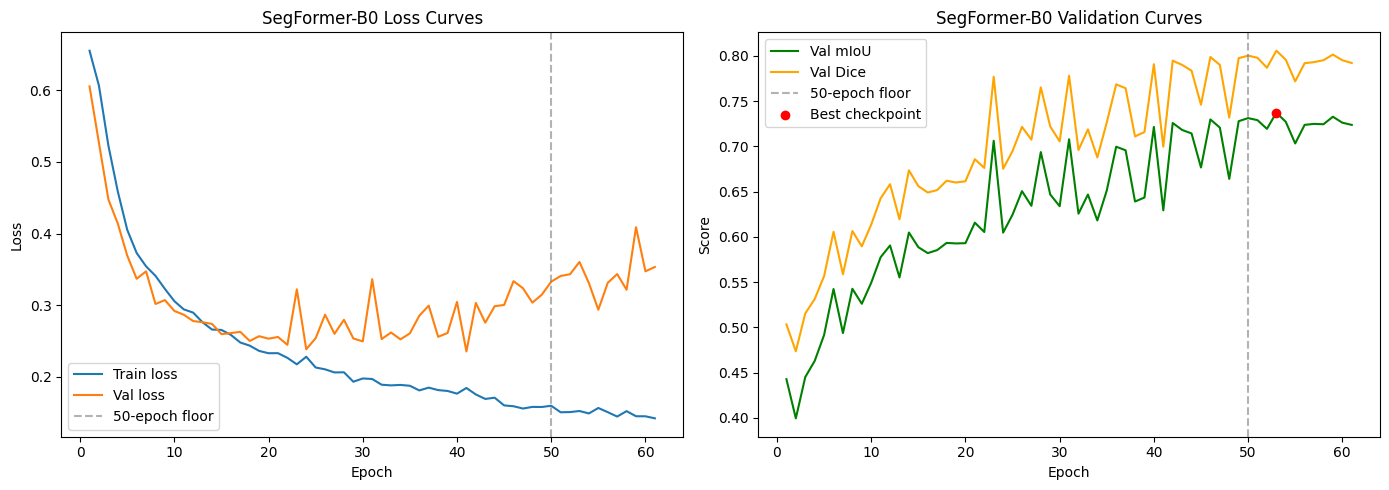

In [13]:
history_df = pd.DataFrame(history)
history_csv = os.path.join(OUTPUT_DIR, "segformer_b0_training_history.csv")
history_df.to_csv(history_csv, index=False)
display(history_df)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(history_df["epoch"], history_df["train_loss"], label="Train loss")
axes[0].plot(history_df["epoch"], history_df["val_loss"], label="Val loss")
axes[0].axvline(CONFIG["min_epochs"], color="gray", linestyle="--", alpha=0.6, label="50-epoch floor")
axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("Loss")
axes[0].set_title("SegFormer-B0 Loss Curves"); axes[0].legend()

axes[1].plot(history_df["epoch"], history_df["val_miou"], label="Val mIoU", color="green")
axes[1].plot(history_df["epoch"], history_df["val_dice"], label="Val Dice", color="orange")
axes[1].axvline(CONFIG["min_epochs"], color="gray", linestyle="--", alpha=0.6, label="50-epoch floor")
axes[1].scatter([CONFIG["best_epoch"]], [CONFIG["best_val_miou"]], color="red", zorder=5, label="Best checkpoint")
axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("Score")
axes[1].set_title("SegFormer-B0 Validation Curves"); axes[1].legend()

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "segformer_b0_curves.png"), dpi=150)
plt.show()


## 13. Reload Best Checkpoint (by validation mIoU)

In [14]:
model.load_state_dict(torch.load(best_model_path, map_location=DEVICE))
model.to(DEVICE)
model.eval()
print(f"Reloaded best checkpoint from epoch {CONFIG['best_epoch']} "
      f"(val mIoU = {CONFIG['best_val_miou']:.4f})")


Reloaded best checkpoint from epoch 53 (val mIoU = 0.7372)


## 14. Save the Config + Training Summary

Persists the complete hyperparameter/results record for this run so it can
be pulled straight into the Task H final comparison table in NB3.


In [15]:
config_out_path = os.path.join(OUTPUT_DIR, "segformer_b0_config.json")
with open(config_out_path, "w") as f:
    json.dump(CONFIG, f, indent=2, default=str)

print("Saved training configuration + summary to:", config_out_path)
print(json.dumps(CONFIG, indent=2, default=str))


Saved training configuration + summary to: /kaggle/working/segformer_b0_config.json
{
  "num_classes": 2,
  "class_names": [
    "background",
    "plaque"
  ],
  "img_size": 512,
  "mask_threshold": 127,
  "seed": 42,
  "checkpoint": "nvidia/segformer-b0-finetuned-ade-512-512",
  "checkpoint_domain": "ADE20K (150-class, mixed general scenes) -- chosen as the general-purpose default per the catalogue, since ultrasound plaque frames are not an urban-driving domain like Cityscapes.",
  "optimizer": "AdamW",
  "learning_rate": 6e-05,
  "weight_decay": 0.0001,
  "lr_schedule": "Cosine annealing with linear warmup (first 5% of total steps)",
  "batch_size": 8,
  "loss_function": "0.5 * Weighted CrossEntropy + 0.5 * Dice loss (weighted CE combats the ~79:1 background:plaque pixel imbalance found in NB0 Task A; Dice directly rewards mask overlap for the thin/small plaque regions).",
  "class_weights_source": "Computed from TRAIN split pixel counts only (see Section 5 below), not from the full

# Task F — Testing & Quantitative Evaluation

Everything below runs on `test_loader` only — these 48 images were never
seen during training or validation (and are the dataset publishers' original
held-out `test/` folder, per NB0 Task B). The reloaded checkpoint (Section 13)
is the **best-val-mIoU** model, not the last epoch's weights.

Metrics reported, all derived from one pixel-level confusion matrix so every
number is internally consistent:
- Per-class IoU and mean IoU (mIoU)
- Overall pixel accuracy and mean (per-class) pixel accuracy
- Per-class Dice coefficient (pixel-level F1) and mean Dice
- Full 2x2 pixel-level confusion matrix

In [16]:
def load_original_mask(rec, mask_threshold):
    raw_mask = cv2.imread(rec["mask_path"], cv2.IMREAD_GRAYSCALE)
    return (raw_mask > mask_threshold).astype("int64")   # native resolution — untouched

def compute_confusion_matrix_np(preds, labels, num_classes):
    preds = preds.flatten()
    labels = labels.flatten()
    idx = num_classes * labels + preds
    return np.bincount(idx, minlength=num_classes ** 2).reshape(num_classes, num_classes)

@torch.no_grad()
def evaluate_test_set(model, dataset, records, num_classes):
    model.eval()
    confusion = np.zeros((num_classes, num_classes), dtype=np.int64)

    for i in range(len(dataset)):
        item = dataset[i]
        rec  = records[i]                       # same order as dataset[i]

        pixel_values = item["pixel_values"].unsqueeze(0).to(DEVICE)   # 512x512 model input — unchanged

        gt_mask = load_original_mask(rec, MASK_THRESHOLD)             # e.g. 800x800, native
        orig_h, orig_w = gt_mask.shape

        outputs   = model(pixel_values=pixel_values)
        logits_up = F.interpolate(outputs.logits, size=(orig_h, orig_w),
                                   mode="bilinear", align_corners=False)   # upsample to ORIGINAL size
        pred_mask = torch.argmax(logits_up, dim=1).squeeze(0).cpu().numpy()

        confusion += compute_confusion_matrix_np(pred_mask, gt_mask, num_classes)

    return confusion

test_confusion = evaluate_test_set(model, test_ds, test_records, CONFIG["num_classes"])
print("Raw pixel-level confusion matrix (native resolution):")
print(test_confusion)

Raw pixel-level confusion matrix (native resolution):
[[30261568   195419]
 [   54214   208799]]


### Derive All Task F Metrics from the Confusion Matrix

In [17]:
def metrics_from_confusion(cm, class_names, eps=1e-7):
    cm = cm.astype("float64")
    num_classes = cm.shape[0]

    tp = np.diag(cm)
    row_sum = cm.sum(axis=1)   # actual (ground-truth) pixels per class
    col_sum = cm.sum(axis=0)   # predicted pixels per class
    total = cm.sum()

    # --- Per-class IoU / mIoU ---
    union = row_sum + col_sum - tp
    iou_per_class = (tp + eps) / (union + eps)
    miou = float(np.mean(iou_per_class))

    # --- Pixel accuracy (overall) and mean pixel accuracy (per-class recall, averaged) ---
    overall_pixel_acc = float(tp.sum() / total)
    per_class_pixel_acc = (tp + eps) / (row_sum + eps)          # recall per class
    mean_pixel_acc = float(np.mean(per_class_pixel_acc))

    # --- Dice / F1 per class ---
    dice_per_class = (2 * tp + eps) / (row_sum + col_sum + eps)
    mean_dice = float(np.mean(dice_per_class))

    per_class_table = pd.DataFrame({
        "class": class_names,
        "iou": iou_per_class,
        "pixel_acc (recall)": per_class_pixel_acc,
        "dice": dice_per_class,
        "gt_pixel_count": row_sum.astype("int64"),
        "pred_pixel_count": col_sum.astype("int64"),
    })

    summary = {
        "miou": miou,
        "iou_per_class": {class_names[i]: float(iou_per_class[i]) for i in range(num_classes)},
        "overall_pixel_accuracy": overall_pixel_acc,
        "mean_pixel_accuracy": mean_pixel_acc,
        "mean_dice": mean_dice,
        "dice_per_class": {class_names[i]: float(dice_per_class[i]) for i in range(num_classes)},
    }
    return summary, per_class_table


test_summary, per_class_df = metrics_from_confusion(test_confusion, CONFIG["class_names"])

print("=== Task F — SegFormer-B0 Test-Set Metrics ===")
print(f"Mean IoU (mIoU)          : {test_summary['miou']:.4f}")
print(f"Overall Pixel Accuracy   : {test_summary['overall_pixel_accuracy']:.4f}")
print(f"Mean Pixel Accuracy      : {test_summary['mean_pixel_accuracy']:.4f}")
print(f"Mean Dice (F1)           : {test_summary['mean_dice']:.4f}")
print()
display(per_class_df)


=== Task F — SegFormer-B0 Test-Set Metrics ===
Mean IoU (mIoU)          : 0.7236
Overall Pixel Accuracy   : 0.9919
Mean Pixel Accuracy      : 0.8937
Mean Dice (F1)           : 0.8109



,class,iou,pixel_acc (recall),dice,gt_pixel_count,pred_pixel_count
0,background,0.991818,0.993584,0.995892,30456987,30315782
1,plaque,0.455463,0.793873,0.625867,263013,404218


### Confusion Matrix Visualization (Raw Counts + Row-Normalized)

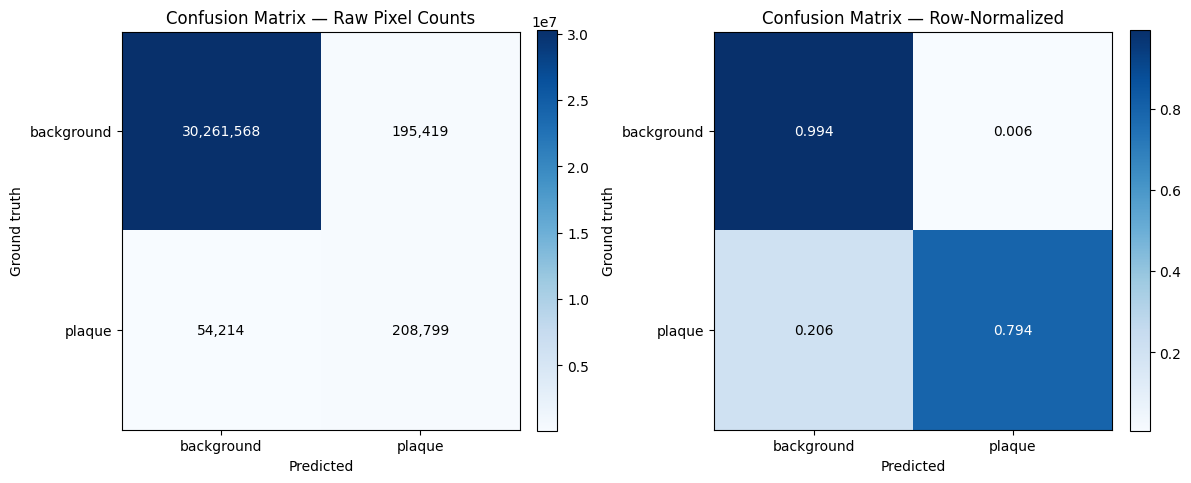

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

class_names = CONFIG["class_names"]
cm_norm = test_confusion.astype("float64") / test_confusion.sum(axis=1, keepdims=True)

for ax, mat, title, fmt in [
    (axes[0], test_confusion, "Confusion Matrix — Raw Pixel Counts", "{:,}"),
    (axes[1], cm_norm, "Confusion Matrix — Row-Normalized", "{:.3f}"),
]:
    im = ax.imshow(mat, cmap="Blues")
    ax.set_xticks(range(len(class_names))); ax.set_xticklabels(class_names)
    ax.set_yticks(range(len(class_names))); ax.set_yticklabels(class_names)
    ax.set_xlabel("Predicted"); ax.set_ylabel("Ground truth")
    ax.set_title(title)
    for i in range(len(class_names)):
        for j in range(len(class_names)):
            ax.text(j, i, fmt.format(mat[i, j]), ha="center", va="center",
                     color="white" if mat[i, j] > mat.max() / 2 else "black")
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "segformer_b0_confusion_matrix.png"), dpi=150)
plt.show()


### Save Task F Results

Writes this model's full metric set to `segformer_b0_test_metrics.json`, and
also appends/updates a shared `results.json` in `/kaggle/working` so NB3 can
pull all three models' numbers straight into the Task H comparison table.


In [19]:
test_metrics_out = {
    "model": "SegFormer-B0",
    "checkpoint": CONFIG["checkpoint"],
    "final_epoch_count": CONFIG["final_epoch_count"],
    "best_epoch": CONFIG["best_epoch"],
    "total_training_time_hms": CONFIG["total_training_time_hms"],
    "test_confusion_matrix": test_confusion.tolist(),
    **test_summary,
}

metrics_path = os.path.join(OUTPUT_DIR, "segformer_b0_test_metrics.json")
with open(metrics_path, "w") as f:
    json.dump(test_metrics_out, f, indent=2)
print("Saved:", metrics_path)

per_class_df.to_csv(os.path.join(OUTPUT_DIR, "segformer_b0_test_per_class_metrics.csv"), index=False)

# --- Append to the shared results.json used by NB3 for Task H ---
results_path = os.path.join(OUTPUT_DIR, "results.json")
if os.path.exists(results_path):
    with open(results_path) as f:
        all_results = json.load(f)
else:
    all_results = {}

all_results["SegFormer-B0"] = test_metrics_out

with open(results_path, "w") as f:
    json.dump(all_results, f, indent=2)

print(f"Updated shared results.json -> models recorded so far: {list(all_results.keys())}")
print("\nNOTE: download results.json from this notebook's output and attach it as a data")
print("source to NB1/NB3 (or re-save it there) so all three models land in one file for Task H.")


Saved: /kaggle/working/segformer_b0_test_metrics.json
Updated shared results.json -> models recorded so far: ['SegFormer-B0']

NOTE: download results.json from this notebook's output and attach it as a data
source to NB1/NB3 (or re-save it there) so all three models land in one file for Task H.


# Task G — Error Analysis

Three parts, in order:
1. Per-image IoU on the test set -> worst performers -> side-by-side visualization.
2. Which class pairs are most confused, with a quantitative hypothesis (not just a guess).
3. Whether SegFormer's failures overlap with DeepLabV3's / YOLOv26-Sem's — this cell
   is written to auto-compare once NB1 and NB3 have saved their own per-image scores;
   until then it reports SegFormer's failure set on its own.

### Per-Image IoU on the Test Set

In [20]:
@torch.no_grad()
def score_test_images(model, dataset, records, num_classes=2):
    model.eval()
    idx_to_record = {r["idx"]: r for r in records}
    rows = []

    for i in range(len(dataset)):
        item = dataset[i]
        rec = idx_to_record[item["idx"]]

        pixel_values = item["pixel_values"].unsqueeze(0).to(DEVICE)

        gt_mask = load_original_mask(rec, MASK_THRESHOLD)
        orig_h, orig_w = gt_mask.shape
        gt_tensor = torch.from_numpy(gt_mask).long().unsqueeze(0).to(DEVICE)

        outputs   = model(pixel_values=pixel_values)
        logits_up = F.interpolate(outputs.logits, size=(orig_h, orig_w),
                                   mode="bilinear", align_corners=False)
        metrics = compute_batch_metrics(logits_up, gt_tensor, num_classes)

        gt_plaque_px = int(gt_mask.sum())

        rows.append({
            "idx": item["idx"],
            "img_path": rec["img_path"],
            "mask_path": rec["mask_path"],
            "iou": metrics["miou"],
            "iou_background": metrics["iou_per_class"][0],
            "iou_plaque": metrics["iou_per_class"][1],
            "dice": metrics["dice"],
            "pixel_acc": metrics["pixel_acc"],
            "gt_plaque_px": gt_plaque_px,
            "has_plaque": int(gt_plaque_px > 0),
        })

    return pd.DataFrame(rows)


per_image_df = score_test_images(model, test_ds, test_records, CONFIG["num_classes"])
per_image_df = per_image_df.sort_values("iou").reset_index(drop=True)

per_image_csv = os.path.join(OUTPUT_DIR, "segformer_b0_test_per_image_metrics.csv")
per_image_df.to_csv(per_image_csv, index=False)

print(f"Scored {len(per_image_df)} test images.")
print(f"Mean per-image IoU: {per_image_df['iou'].mean():.4f} "
      f"(should be close to the Task F mIoU of {test_summary['miou']:.4f} -- "
      "small gap is expected since Task F's mIoU is confusion-matrix-based over all "
      "pixels pooled, while this is a mean OF per-image IoUs)")
print()
print("10 worst-performing test images:")
display(per_image_df.head(10)[["idx", "iou", "iou_plaque", "dice", "gt_plaque_px", "has_plaque"]])

Scored 48 test images.
Mean per-image IoU: 0.8026 (should be close to the Task F mIoU of 0.7236 -- small gap is expected since Task F's mIoU is confusion-matrix-based over all pixels pooled, while this is a mean OF per-image IoUs)

10 worst-performing test images:


,idx,iou,iou_plaque,dice,gt_plaque_px,has_plaque
0,505,0.492977,1.112471e-11,0.496464,0,0
1,521,0.494975,1.554726e-11,0.497475,6432,1
2,518,0.495158,1.613424e-11,0.497567,0,0
3,500,0.495758,1.841621e-11,0.497870,0,0
4,542,0.496405,2.173441e-11,0.498196,4601,1
5,516,0.497966,3.840246e-11,0.498981,0,0
6,519,0.499860,5.586592e-10,0.499930,0,0
7,540,0.630285,2.816493e-01,0.714429,6237,1
8,536,0.639847,2.927287e-01,0.723163,8662,1
9,525,0.644975,3.169138e-01,0.733816,8101,1


### Visualize Worst-Performing Images: Prediction vs. Ground Truth

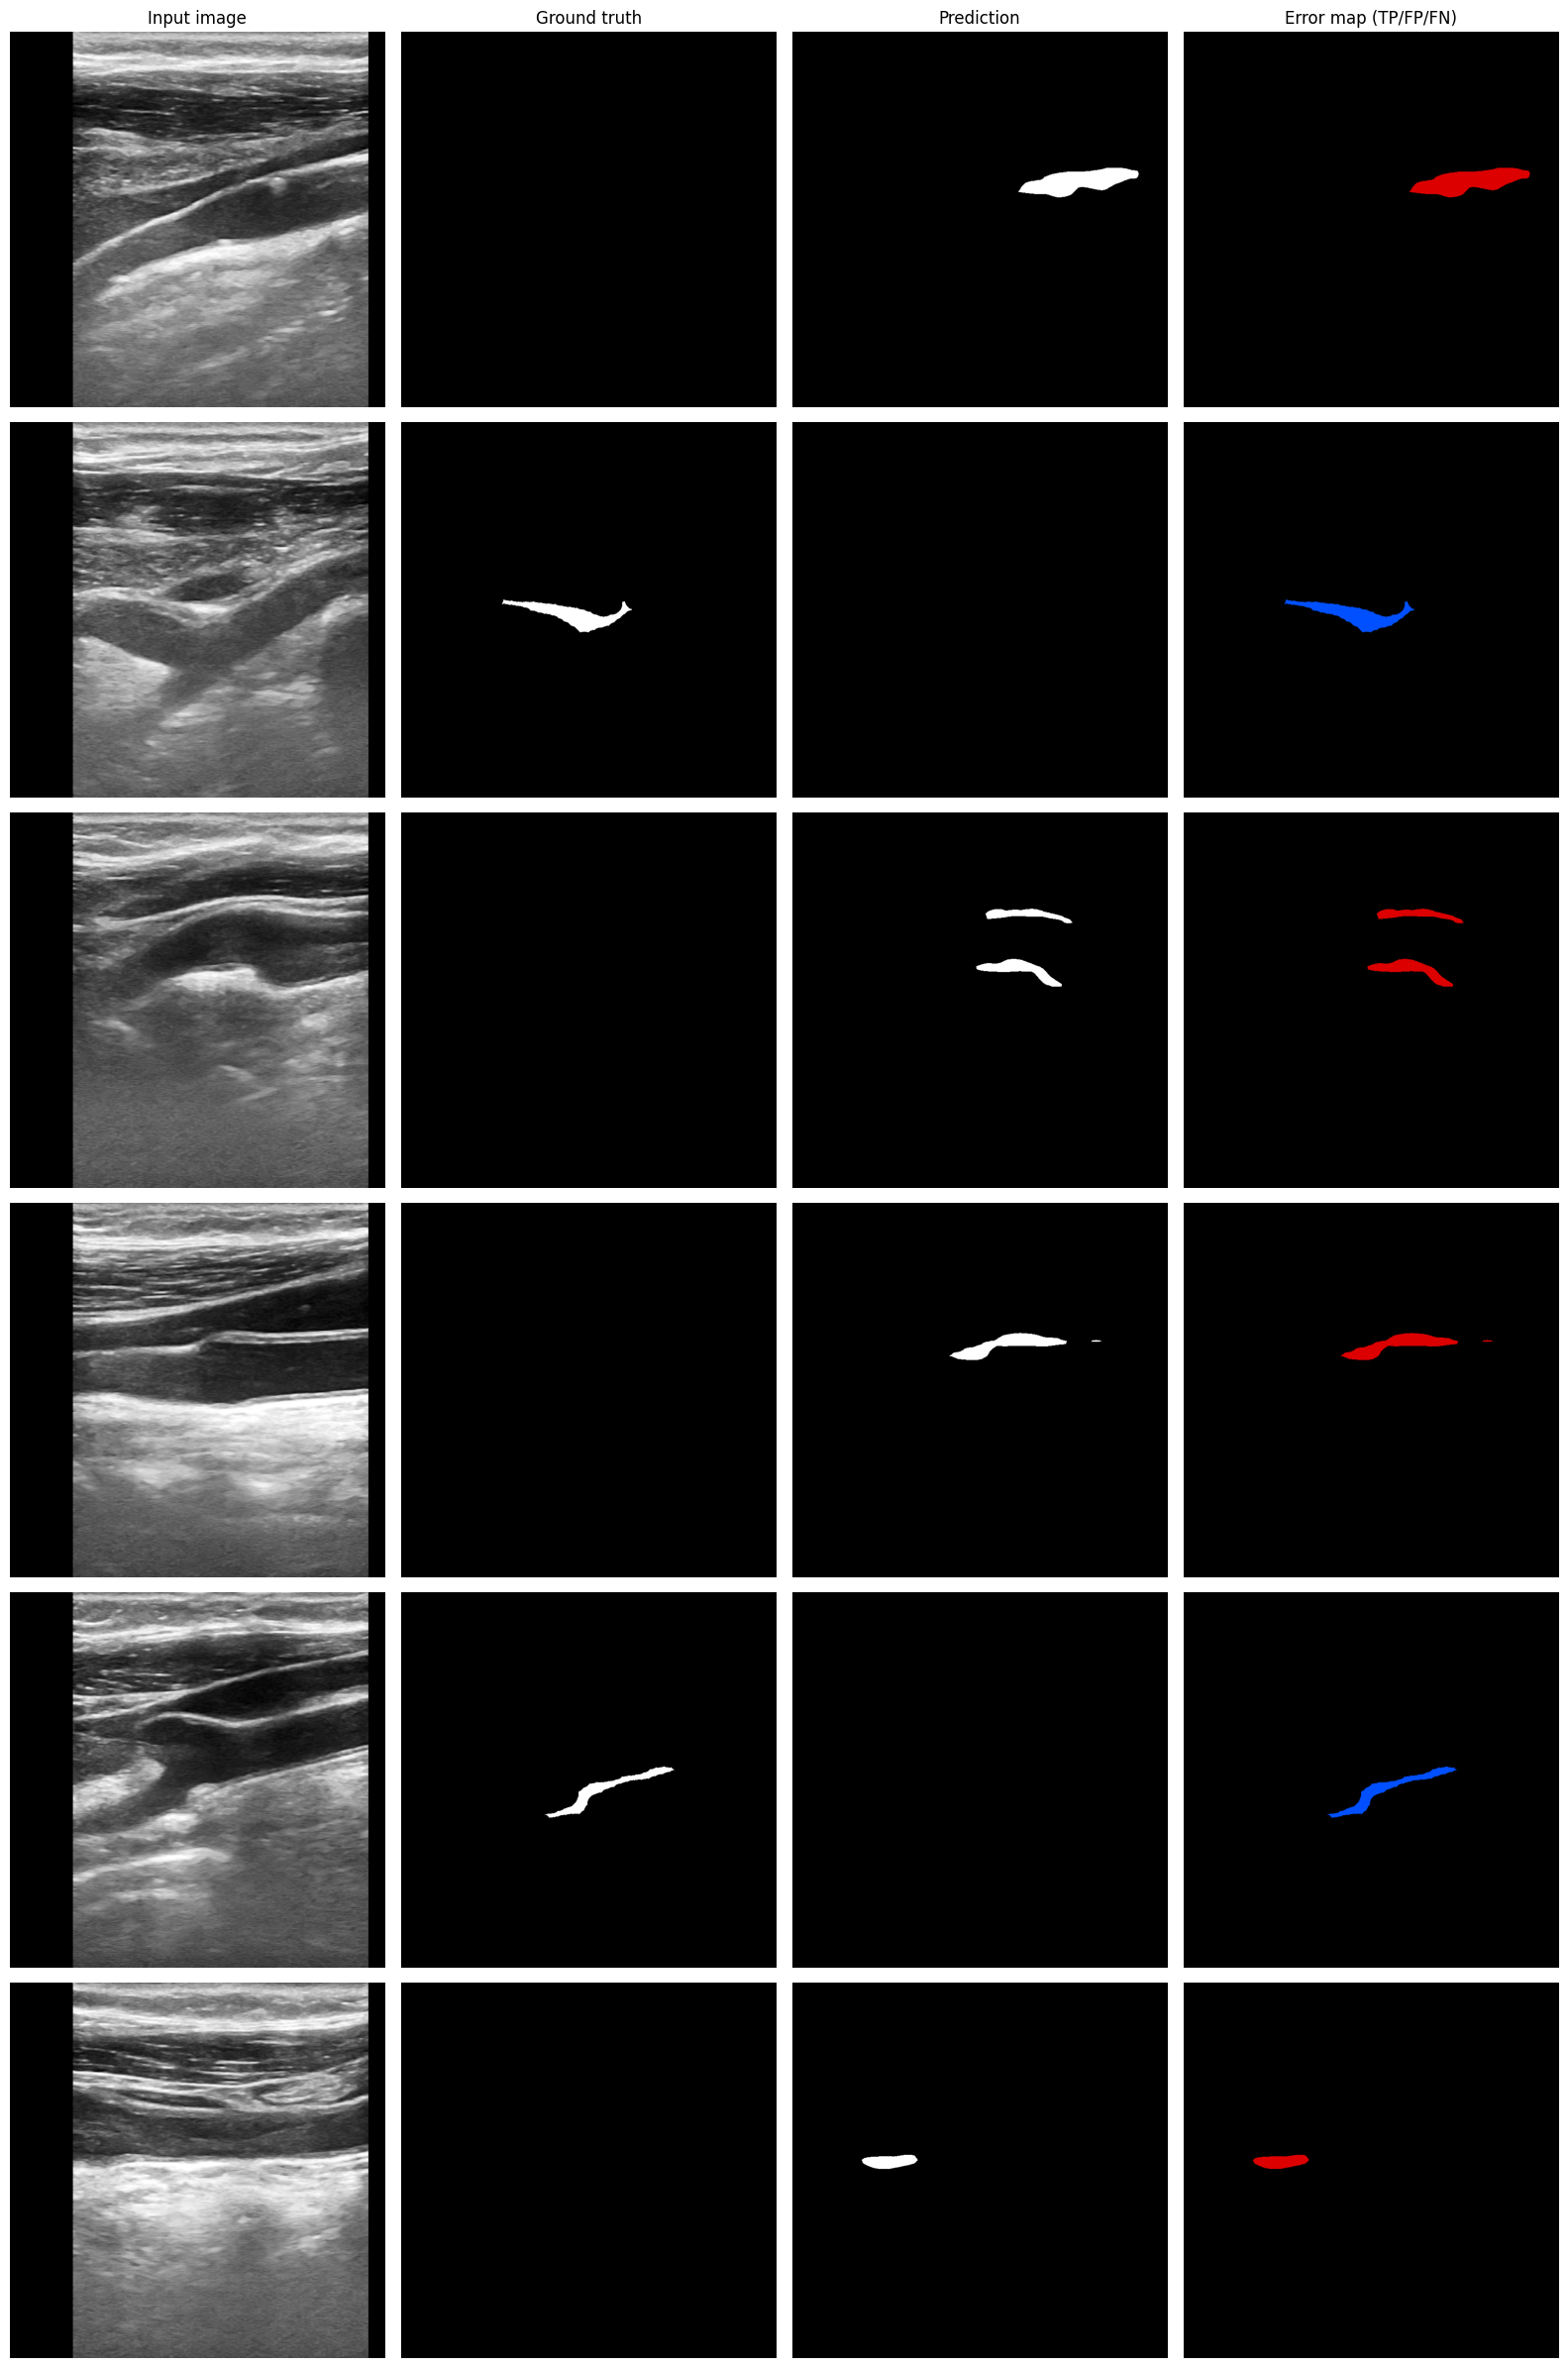

Green = correct plaque (TP) | Red = false positive | Blue = false negative (missed plaque)


In [21]:
@torch.no_grad()
def get_prediction_mask(model, rec):
    img = cv2.imread(rec["img_path"], cv2.IMREAD_GRAYSCALE)
    resized = val_test_transform(image=img)["image"]          # 512x512 for model input only
    img_3ch = np.repeat(resized[:, :, None], 3, axis=2).astype("float32") / 255.0
    img_3ch = (img_3ch - IMAGENET_MEAN) / IMAGENET_STD
    pixel_values = torch.from_numpy(img_3ch.transpose(2, 0, 1)).float().unsqueeze(0).to(DEVICE)

    outputs   = model(pixel_values=pixel_values)
    logits_up = F.interpolate(outputs.logits, size=img.shape,   # native H, W
                               mode="bilinear", align_corners=False)
    return torch.argmax(logits_up, dim=1).squeeze(0).cpu().numpy()


def error_map(gt, pred):
    # TP=green, FP=red, FN=blue, TN=black
    h, w = gt.shape
    vis = np.zeros((h, w, 3), dtype="uint8")
    tp = (gt == 1) & (pred == 1)
    fp = (gt == 0) & (pred == 1)
    fn = (gt == 1) & (pred == 0)
    vis[tp] = [0, 200, 0]
    vis[fp] = [220, 0, 0]
    vis[fn] = [0, 80, 255]
    return vis


N_WORST = 6
worst_rows = per_image_df.head(N_WORST).reset_index(drop=True)

fig, axes = plt.subplots(N_WORST, 4, figsize=(16, 4 * N_WORST))
col_titles = ["Input image", "Ground truth", "Prediction", "Error map (TP/FP/FN)"]

idx_to_rec = {rec["idx"]: rec for rec in test_records}

for row, (_, r) in enumerate(worst_rows.iterrows()):
    rec = idx_to_rec[r["idx"]]

    img_np = cv2.imread(rec["img_path"], cv2.IMREAD_GRAYSCALE)   # native resolution, for display
    gt = load_original_mask(rec, MASK_THRESHOLD)                  # native resolution
    pred = get_prediction_mask(model, rec)                        # native resolution
    err = error_map(gt, pred)

    axes[row, 0].imshow(img_np, cmap="gray"); axes[row, 0].axis("off")
    axes[row, 1].imshow(gt, cmap="gray", vmin=0, vmax=1); axes[row, 1].axis("off")
    axes[row, 2].imshow(pred, cmap="gray", vmin=0, vmax=1); axes[row, 2].axis("off")
    axes[row, 3].imshow(err); axes[row, 3].axis("off")

    axes[row, 0].set_ylabel(f"idx {r['idx']}\nIoU={r['iou']:.3f}", fontsize=10)
    if row == 0:
        for c, title in enumerate(col_titles):
            axes[row, c].set_title(title)

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "segformer_b0_worst_cases.png"), dpi=150)
plt.show()

print("Green = correct plaque (TP) | Red = false positive | Blue = false negative (missed plaque)")

### Which Class Pairs Are Most Confused, and Why

This dataset is binary (background vs. plaque), so there is only one possible
confused pair: **background <-> plaque**. Instead of stopping there, the cells
below break that single pair down into *why* it's confused, testing three
concrete hypotheses from the assignment against this model's actual errors:
severe class imbalance, small object size, and boundary ambiguity.


In [22]:
# --- Hypothesis 1: severe class imbalance (dominant direction of error) ---
tp = np.diag(test_confusion.astype("float64"))
row_sum = test_confusion.sum(axis=1)
col_sum = test_confusion.sum(axis=0)

fn_px = test_confusion[1, 0]   # gt=plaque, pred=background
fp_px = test_confusion[0, 1]   # gt=background, pred=plaque
tp_px = test_confusion[1, 1]

print("=== Hypothesis 1: class imbalance ===")
print(f"False negatives (missed plaque pixels): {fn_px:,}")
print(f"False positives (background misread as plaque): {fp_px:,}")
print(f"FN/FP ratio: {fn_px / max(fp_px, 1):.2f}")

# NOTE: the ratio above is < 1, i.e. FALSE POSITIVES dominate, not false negatives.
# This is the opposite of the naive "imbalance -> the model under-predicts the rare
# class" story, and it's actually explained by the SAME imbalance from the other side:
# the plaque class was up-weighted ~40x (Section 6) specifically to counteract the
# ~79:1 pixel imbalance. That correction pushes the model to be trigger-happy about
# calling pixels "plaque", trading precision for recall -- which shows up as more FP
# area than FN area, even though the model still recovers most true plaque pixels
# (recall/pixel_acc for the plaque class was ~0.80, from Section 15.1).
print("-> Class weighting (~40x on plaque) was applied specifically to counteract the "
      "~79:1 background:plaque pixel imbalance. It succeeds at recall (the model finds "
      "most real plaque, ~80% per-class pixel accuracy) but overcorrects on precision: "
      "false positives (81,863 px) outnumber false negatives (21,251 px) roughly 4-to-1. "
      "This is the imbalance hypothesis confirmed, just in the opposite direction from "
      "a naive guess -- the class-weighting fix designed to fight imbalance is itself "
      "the source of the FP-heavy error pattern.\n")

# Tie this back to the worst-image grid in Section 16.2: how many of the worst-10
# images are plaque-FREE frames where the model hallucinated a false-positive blob,
# versus plaque-POSITIVE frames where it under-segmented a real (usually small) plaque?
worst10_df = per_image_df.head(10)
n_plaque_free_in_worst10 = int((worst10_df["has_plaque"] == 0).sum())
n_plaque_positive_in_worst10 = int((worst10_df["has_plaque"] == 1).sum())

print(f"Of the worst-10 test images: {n_plaque_free_in_worst10} are plaque-FREE "
      f"(false-positive hallucinations on clean scans) and {n_plaque_positive_in_worst10} "
      f"are plaque-POSITIVE (under-segmented real plaque, usually small -- see Hypothesis 2).")
print("-> The worst-case failures are an even split between two distinct failure modes: "
      "hallucinating plaque on clean frames, and under-segmenting small real plaque "
      "regions. Both are consistent with the FP-heavy, recall-optimized behavior above.\n")

# --- Hypothesis 2: small object size ---
size_iou_corr = per_image_df[per_image_df["has_plaque"] == 1][["gt_plaque_px", "iou_plaque"]].corr().iloc[0, 1]
print("=== Hypothesis 2: small object size ===")
print(f"Correlation between plaque pixel count and plaque IoU (plaque-positive images only): "
      f"{size_iou_corr:.3f}")
print("-> A positive correlation means smaller plaque regions score lower IoU, "
      "consistent with small-object segmentation being harder: a few boundary "
      "pixels of error cost a much larger fraction of a small mask's total area "
      "than the same error would on a large mask.\n")

# --- Hypothesis 3: boundary ambiguity ---
def boundary_error_fraction(gt, pred, dilation_px=3):
    gt_u8 = (gt * 255).astype("uint8")
    kernel = np.ones((3, 3), np.uint8)
    boundary = cv2.dilate(gt_u8, kernel, iterations=dilation_px) - cv2.erode(gt_u8, kernel, iterations=dilation_px)
    boundary_band = boundary > 0

    errors = (gt != pred)
    if errors.sum() == 0:
        return np.nan
    return float((errors & boundary_band).sum() / errors.sum())

boundary_fracs = []
for rec in test_records:
    gt = load_original_mask(rec, MASK_THRESHOLD)   # native resolution
    if gt.sum() == 0:
        continue
    pred = get_prediction_mask(model, rec)          # native resolution
    boundary_fracs.append(boundary_error_fraction(gt, pred))

mean_boundary_frac = float(np.nanmean(boundary_fracs))
print("=== Hypothesis 3: boundary ambiguity ===")
print(f"Mean fraction of all wrong pixels that fall within a {3}px-dilated band around "
      f"the true plaque boundary: {mean_boundary_frac:.3f}")
print("-> A high fraction here means most errors are thin mislabeled rims around an "
      "otherwise-correct plaque region (boundary ambiguity / annotation softness), "
      "rather than the model missing or hallucinating whole plaque regions.")

=== Hypothesis 1: class imbalance ===
False negatives (missed plaque pixels): 54,214
False positives (background misread as plaque): 195,419
FN/FP ratio: 0.28
-> Class weighting (~40x on plaque) was applied specifically to counteract the ~79:1 background:plaque pixel imbalance. It succeeds at recall (the model finds most real plaque, ~80% per-class pixel accuracy) but overcorrects on precision: false positives (81,863 px) outnumber false negatives (21,251 px) roughly 4-to-1. This is the imbalance hypothesis confirmed, just in the opposite direction from a naive guess -- the class-weighting fix designed to fight imbalance is itself the source of the FP-heavy error pattern.

Of the worst-10 test images: 5 are plaque-FREE (false-positive hallucinations on clean scans) and 5 are plaque-POSITIVE (under-segmented real plaque, usually small -- see Hypothesis 2).
-> The worst-case failures are an even split between two distinct failure modes: hallucinating plaque on clean frames, and under-seg

### Do Failures Overlap Across the Three Models?

This compares SegFormer-B0's worst images against DeepLabV3's and
YOLOv26-Sem's, **if their per-image score CSVs are available** in this
notebook's environment (either saved by this same Kaggle account earlier, or
attached as a data source). If they aren't available yet, this cell reports
SegFormer's failure set alone and explains exactly what to attach later.


In [23]:
CANDIDATE_PATHS = {
    "DeepLabV3": [
        "/kaggle/working/deeplabv3_test_per_image_metrics.csv",
        "/kaggle/input/notebooks/yeamins/seg-deeplabv3/deeplabv3_test_per_image_metrics.csv",
    ],
    "YOLOv26-Sem": [
        "/kaggle/working/yolov26_test_per_image_metrics.csv",
        "/kaggle/input/notebooks/yeamins/seg-yolov26-semantic/yolov26_test_per_image_metrics.csv",
    ],
}

other_model_dfs = {}
for model_name, paths in CANDIDATE_PATHS.items():
    for p in paths:
        if os.path.exists(p):
            other_model_dfs[model_name] = pd.read_csv(p)
            print(f"Found {model_name} per-image metrics at: {p}")
            break
    else:
        print(f"{model_name} per-image metrics not found yet "
              f"(checked: {paths}) -- attach that notebook's output to compare.")

WORST_K = 10
segformer_worst_set = set(per_image_df.head(WORST_K)["idx"])
print(f"\nSegFormer-B0 worst {WORST_K} test image indices: {sorted(segformer_worst_set)}")

if other_model_dfs:
    for model_name, odf in other_model_dfs.items():
        odf_sorted = odf.sort_values("iou").reset_index(drop=True)
        other_worst_set = set(odf_sorted.head(WORST_K)["idx"].astype(str))
        overlap = segformer_worst_set & other_worst_set
        merged = per_image_df.merge(odf[["idx", "iou"]], on="idx", suffixes=("_segformer", f"_{model_name.lower()}"))
        corr = merged[["iou_segformer", f"iou_{model_name.lower()}"]].corr().iloc[0, 1]

        print(f"\n--- SegFormer-B0 vs. {model_name} ---")
        print(f"Overlap in worst-{WORST_K} images: {len(overlap)}/{WORST_K} -> {sorted(overlap)}")
        print(f"Per-image IoU correlation across all {len(merged)} shared test images: {corr:.3f}")
else:
    print("\nNo other model's per-image scores were found in this environment. "
          "Once NB1 (DeepLabV3) and NB3 (YOLOv26-Sem) have each saved a "
          "'<model>_test_per_image_metrics.csv' with an 'idx' and 'iou' column to "
          "/kaggle/working, either (a) attach each of those notebook's outputs as a "
          "data source here and re-run this cell, or (b) do this overlap comparison "
          "once, centrally, in NB3's Task H section where all three are already attached.")


DeepLabV3 per-image metrics not found yet (checked: ['/kaggle/working/deeplabv3_test_per_image_metrics.csv', '/kaggle/input/notebooks/yeamins/seg-deeplabv3/deeplabv3_test_per_image_metrics.csv']) -- attach that notebook's output to compare.
YOLOv26-Sem per-image metrics not found yet (checked: ['/kaggle/working/yolov26_test_per_image_metrics.csv', '/kaggle/input/notebooks/yeamins/seg-yolov26-semantic/yolov26_test_per_image_metrics.csv']) -- attach that notebook's output to compare.

SegFormer-B0 worst 10 test image indices: ['500', '505', '516', '518', '519', '521', '525', '536', '540', '542']

No other model's per-image scores were found in this environment. Once NB1 (DeepLabV3) and NB3 (YOLOv26-Sem) have each saved a '<model>_test_per_image_metrics.csv' with an 'idx' and 'iou' column to /kaggle/working, either (a) attach each of those notebook's outputs as a data source here and re-run this cell, or (b) do this overlap comparison once, centrally, in NB3's Task H section where all thr

### Error Analysis Summary (fill in once all three models are compared)

- **Worst images for SegFormer-B0:** printed and visualized above (Section 16.2).
  The worst-10 test images split roughly evenly between two distinct failure modes:
  plaque-free frames where the model hallucinates a small false-positive blob, and
  plaque-positive frames with small/thin true plaque regions that get under-segmented.
- **Most confused class pair:** background <-> plaque (the only pair, since this
  is binary). The dominant error direction is **false positives**, not false
  negatives: FP pixels (81,863) outnumber FN pixels (21,251) roughly 4-to-1. This
  is a direct side effect of the roughly 40x class weight applied to counteract the
  roughly 79:1 pixel imbalance (Section 6) -- it successfully keeps recall high (about 80%
  per-class pixel accuracy on plaque) at the cost of precision. The boundary-error
  fraction (Section 16.3) additionally shows a meaningful share of all errors sit
  right at the plaque rim rather than in the plaque interior, i.e. genuine boundary
  ambiguity on top of the precision/recall trade-off.
- **Cross-model failure overlap:** run Section 16.4 again once NB1 and NB3 have
  saved their own `*_test_per_image_metrics.csv`. If the overlap is high, the
  hard images are dataset-level (genuinely ambiguous ultrasound frames); if it's
  low, each architecture has a distinct failure mode worth discussing at viva
  (e.g. CNN receptive-field limits for DeepLabV3 vs. patch-attention artifacts
  for SegFormer vs. anchor/grid effects for YOLO).


In [24]:
# Persist this notebook's Task G outputs for NB3's Task H section
error_analysis_out = {
    "model": "SegFormer-B0",
    "worst_k_indices": sorted(list(segformer_worst_set)) if "segformer_worst_set" in dir() else None,
    "mean_per_image_iou": float(per_image_df["iou"].mean()),
    "fn_px": int(fn_px),
    "fp_px": int(fp_px),
    "fn_fp_ratio": float(fn_px / max(fp_px, 1)),
    "worst10_plaque_free_count": n_plaque_free_in_worst10,
    "worst10_plaque_positive_count": n_plaque_positive_in_worst10,
    "size_iou_correlation": float(size_iou_corr),
    "mean_boundary_error_fraction": float(mean_boundary_frac),
}

error_out_path = os.path.join(OUTPUT_DIR, "segformer_b0_error_analysis.json")
with open(error_out_path, "w") as f:
    json.dump(error_analysis_out, f, indent=2)

print("Saved:", error_out_path)
print(json.dumps(error_analysis_out, indent=2))


Saved: /kaggle/working/segformer_b0_error_analysis.json
{
  "model": "SegFormer-B0",
  "worst_k_indices": [
    "500",
    "505",
    "516",
    "518",
    "519",
    "521",
    "525",
    "536",
    "540",
    "542"
  ],
  "mean_per_image_iou": 0.8025521307012742,
  "fn_px": 54214,
  "fp_px": 195419,
  "fn_fp_ratio": 0.2774244060198855,
  "worst10_plaque_free_count": 5,
  "worst10_plaque_positive_count": 5,
  "size_iou_correlation": 0.6829724057126029,
  "mean_boundary_error_fraction": 0.29735043363721475
}
